# Hybrid (linear + XGBoost) with PFSS and WSA features (not built)

**The question:** can the hybrid's trees use the magnetic-map inputs (expansion factor,
boundary distance, WSA/HUX speed) that the linear model could not?

- **Anchor:** the submitted linear config (with `pfss_d_hcs_lead_72h`), refitted per fold.
- **Trees:** the hybrid's regressors, official weights at blend 0.1, fitted on every hour.
- **Variants:** + PFSS ring strips (38 columns), + WSA speed (6 lags), both.
- **Rule, set before running:** keep a hybrid variant only if > 1% better than the submitted linear model and winning ≥ 4 of 6 folds.

Study: `python -m training.hybrid_pfss`; results `src/experiments/hybrid_pfss.csv`; write-up `docs/hybrid_pfss.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import hybrid_pfss as hp

d = pd.read_csv(hp.EXPERIMENTS / "hybrid_pfss.csv").set_index("fold")
variants = [v for v in hp.VARIANTS if v != "linear shipped"]
rel = d[variants].div(d["linear shipped"], axis=0)
rel_h = d[variants].div(d["hybrid"], axis=0)


def gmean(r):
    return 100 * (np.exp(np.log(r).mean()) - 1)


summary = pd.DataFrame({
    "/ persistence": np.exp(np.log(d[list(hp.VARIANTS)].div(d["persistence"], axis=0)).mean()),
    "vs linear %": gmean(rel),
    "folds won": (rel < 1).sum(),
    "vs hybrid %": gmean(rel_h),
}).sort_values("/ persistence")
summary["keep"] = ((summary["vs linear %"] < -100 * hp.KEEP_GAIN)
                   & (summary["folds won"] >= hp.KEEP_FOLDS))
summary.round(3)

,/ persistence,vs linear %,folds won,vs hybrid %,keep
hybrid + wsa,0.779,-0.098,2.0,-0.215,False
linear shipped,0.779,NaN,NaN,NaN,False
hybrid,0.780,0.117,2.0,0.000,False
hybrid + pfss + wsa,0.787,1.007,2.0,0.889,False
hybrid + pfss,0.791,1.507,1.0,1.388,False


## 1. Against the submitted linear model, by fold

,hybrid,hybrid + pfss,hybrid + wsa,hybrid + pfss + wsa
fold,,,,
2019,0.28,1.31,0.64,1.46
2020,0.99,1.23,0.26,1.05
2021,1.92,4.84,2.15,4.69
2022,-0.10,1.92,-1.20,0.29
2023,-3.13,0.33,-2.87,-0.32
2024,0.82,-0.51,0.52,-1.02


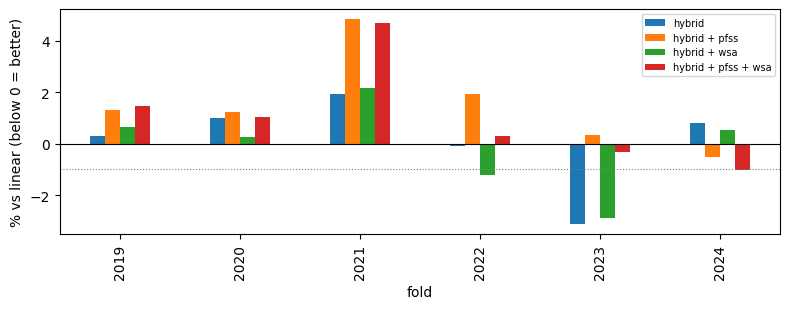

In [2]:
ax = (100 * (rel - 1)).plot.bar(figsize=(8, 3.2))
ax.axhline(0, color="k", lw=.8)
ax.axhline(-100 * hp.KEEP_GAIN, color="grey", ls=":", lw=.8)
ax.set_ylabel("% vs linear (below 0 = better)")
ax.legend(fontsize=7)
plt.tight_layout()
(100 * (rel - 1)).round(2)

No variant wins more than 2 folds. The plain hybrid's gain is the 2023 fold alone; hybrid +
WSA is the best variant at −0.10%.

## 2. Do the new columns help the trees at all?

,hybrid + pfss,hybrid + wsa,hybrid + pfss + wsa
fold,,,
2019,1.02,0.35,1.17
2020,0.24,-0.72,0.06
2021,2.87,0.23,2.72
2022,2.02,-1.11,0.38
2023,3.57,0.27,2.91
2024,-1.32,-0.30,-1.83


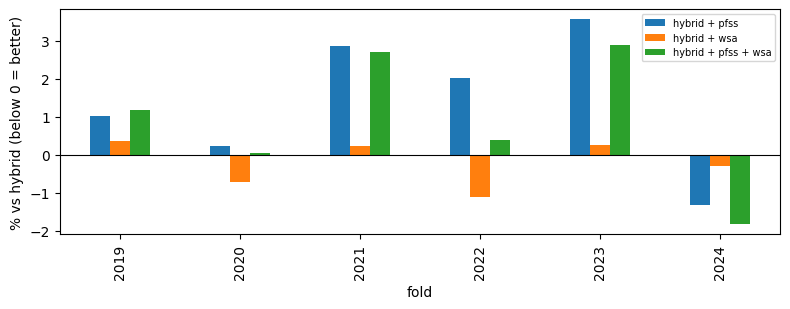

In [3]:
cols = [v for v in variants if v != "hybrid"]
ax = (100 * (rel_h[cols] - 1)).plot.bar(figsize=(8, 3.2))
ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("% vs hybrid (below 0 = better)")
ax.legend(fontsize=7)
plt.tight_layout()
(100 * (rel_h[cols] - 1)).round(2)

- **The PFSS ring strips make the trees worse** in 5 of 6 folds (up to +3.6%, 2023). Only the 2024 fold, the pilot, improved.
- **WSA is roughly neutral** (−0.2% on average): it helps the 2020, 2022 and 2024 folds (−0.3 to −1.1%) and hurts the other three slightly.

The ring columns are correlated (one map, neighbouring longitudes, repeated for 12 h of
hourly rows) and the trees fit the training years' particular streams.

## 3. Scores against persistence

,linear shipped,hybrid,hybrid + pfss,hybrid + wsa,hybrid + pfss + wsa
fold,,,,,
2019,0.7202,0.7223,0.7297,0.7248,0.7308
2020,0.6914,0.6982,0.6999,0.6932,0.6986
2021,0.8086,0.8241,0.8477,0.8259,0.8465
2022,0.8516,0.8508,0.8680,0.8414,0.8541
2023,0.8327,0.8067,0.8355,0.8088,0.8301
2024,0.7849,0.7914,0.7809,0.7890,0.7769


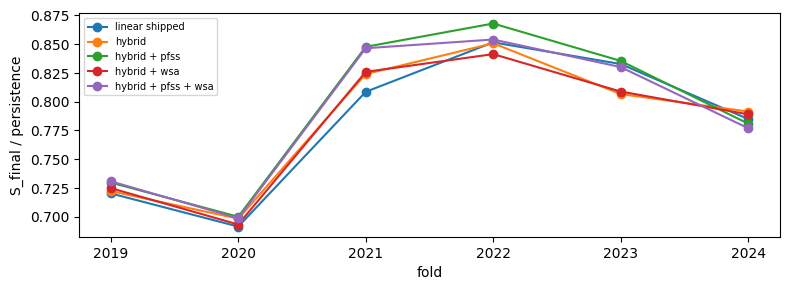

In [4]:
ratio = d[list(hp.VARIANTS)].div(d["persistence"], axis=0)
ax = ratio.plot(marker="o", figsize=(8, 3))
ax.set_ylabel("S_final / persistence")
ax.legend(fontsize=7)
plt.tight_layout()
ratio.round(4)